# Exploratory data analysis (EDA), statistical tests and map

**This Jupyter notebook does the following:**

- Reads the data from the SQLite database `Data/topic1_apartments.db` (SQL query with `JOIN`)
- **Non-graphical EDA:** summary statistics, quantiles, skewness and kurtosis, frequency tables, cross tables, pivot tables, correlation matrix
- **Graphical EDA:** histogram, boxplots, bar chart, scatterplots, correlation heatmap
- **Geographical data:** map of the apartments (folium) and a map by municipality
- **Statistical tests (with p-values):** ANOVA of the net rent per m² by renovation group, Chi-squared test (renovation group × language region), Pearson and Spearman correlations

The structure follows `Week_10/exploratory_data_analysis_apartment_data.ipynb` and the notebooks of Week 12.

## Libraries and settings

In [1]:
# Libraries
import os
import sqlite3
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt
import folium
from scipy.stats import chi2, chi2_contingency
from statsmodels.stats.oneway import anova_oneway

# Settings for seaborn
sns.set_theme(style="ticks", palette="pastel")

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Show current working directory
print(os.getcwd())

C:\Users\DELL\Documents\applied_research_methods\Project_Topic1


## Importing the data from the database

In [2]:
conn = sqlite3.connect('./Data/topic1_apartments.db')

df = pd.read_sql_query('''SELECT a.*, m.bfs_name, m.canton, m.language_region, m.population, m.population_density,
                                 m.foreigners_pct, m.employees, m.mean_taxable_income
                          FROM apartments AS a
                          JOIN municipalities AS m ON a.bfs_number = m.bfs_number''', con=conn)
conn.close()

# Order of the renovation groups in tables and plots
groups = ['not renovated', 'general renovation', 'energy renovation']
colors = {'not renovated': 'grey', 'general renovation': 'tab:blue', 'energy renovation': 'tab:green'}
df['renovation_group'] = pd.Categorical(df['renovation_group'], categories=groups, ordered=True)

print('Dimension:', df.shape)
df.head()

Dimension: (726, 41)


,apartment_id,source,listing_url,address,zip,locality,bfs_number,lat,lon,rooms,...,energy_minergie,renovated_parts,bfs_name,canton,language_region,population,population_density,foreigners_pct,employees,mean_taxable_income
0,1,immoscout24,https://www.immoscout24.ch/mieten/4003651317,"Croix Fédérale 44, 2300 La Chaux-de-Fonds",2300,La Chaux-de-Fonds,6421,47.100984,6.826321,4.5,...,0,not specified,La Chaux-de-Fonds,NE,French,37494,672.900215,30.287513,26383.0,61004.620484
1,2,immoscout24,https://www.immoscout24.ch/mieten/4003652268,"Grüttbachstr. 6, 4542 Luterbach",4542,Luterbach,2527,47.214670,7.583653,4.5,...,0,not specified,Luterbach,SO,German,3488,771.681416,19.323394,1270.0,61860.606061
2,3,immoscout24,https://www.immoscout24.ch/mieten/4003652272,"Neuhofstr. 20, 5600 Lenzburg",5600,Lenzburg,4201,47.387900,8.176346,4.5,...,0,"kitchen, bathroom, windows",Lenzburg,AG,German,10822,956.852343,28.405101,9767.0,74092.307692
3,4,immoscout24,https://www.immoscout24.ch/mieten/4003653122,"Aathalstr. 19, 8610 Uster",8610,Uster,198,47.348583,8.718129,5.5,...,0,none,Uster,ZH,German,35007,1228.746929,23.009684,17237.0,78620.738763
4,5,immoscout24,https://www.immoscout24.ch/mieten/4003653124,"Rte de Bertigny 2/4, 1700 Fribourg",1700,Fribourg,2196,46.805149,7.155283,2.0,...,0,not specified,Fribourg,FR,French,38197,4116.056034,36.704453,33399.0,65882.389480


## Univariate non-graphical EDA

### Summary statistics of the numeric variables

In [3]:
num_cols = ['rooms', 'area', 'price', 'price_net', 'rent_per_m2', 'rent_net_per_m2',
            'building_age', 'population_density', 'foreigners_pct', 'mean_taxable_income']
df[num_cols].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
rooms,726.0,3.6,1.1,1.0,3.0,3.5,4.5,8.0
area,700.0,86.5,31.2,20.0,66.0,82.0,101.0,244.0
price,726.0,1971.1,823.0,680.0,1500.0,1800.0,2220.0,8955.0
price_net,576.0,1719.2,773.3,600.0,1280.0,1550.0,1910.0,8330.0
rent_per_m2,700.0,23.9,7.8,10.6,18.9,22.0,26.6,57.3
rent_net_per_m2,554.0,20.9,7.4,9.6,16.1,19.2,23.7,51.8
building_age,714.0,79.0,57.7,37.0,48.0,61.0,92.0,548.0
population_density,726.0,1847.2,2474.3,4.2,347.2,942.3,2227.2,12811.0
foreigners_pct,726.0,26.9,10.8,2.9,19.5,26.6,34.0,54.8
mean_taxable_income,717.0,71888.9,17426.1,37839.8,62482.2,68263.0,76696.1,229181.9


### Quantiles of the target variable and the main control variables

In [4]:
df[['rent_net_per_m2', 'rent_per_m2', 'area', 'rooms', 'building_age']].quantile(q=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]).round(2)

,rent_net_per_m2,rent_per_m2,area,rooms,building_age
0.05,13.01,15.00,41.95,2.0,39.0
0.10,14.24,16.24,55.00,2.5,41.0
0.25,16.10,18.89,66.00,3.0,48.0
0.50,19.15,22.04,82.00,3.5,61.0
0.75,23.72,26.63,101.00,4.5,92.0
0.90,29.82,34.92,125.00,4.5,126.0
0.95,36.87,40.87,145.00,5.5,165.0


### Skewness and kurtosis

Skewness > 0: long tail to the right (a few very high values). Kurtosis > 0: more extreme values than a normal distribution.

In [5]:
pd.DataFrame({'skewness': df[num_cols].skew(), 'kurtosis': df[num_cols].kurtosis()}).round(2)

,skewness,kurtosis
rooms,0.16,0.71
area,1.03,2.44
price,2.44,10.83
price_net,2.76,13.52
rent_per_m2,1.47,2.42
rent_net_per_m2,1.63,3.06
building_age,4.09,23.42
population_density,2.68,8.01
foreigners_pct,0.13,-0.23
mean_taxable_income,3.83,24.71


### Extreme values: the 5 highest net rents per m²

In [6]:
df.nlargest(5, 'rent_net_per_m2')[['address', 'bfs_name', 'rooms', 'area', 'price_net', 'rent_net_per_m2', 'renovation_group']]

,address,bfs_name,rooms,area,price_net,rent_net_per_m2,renovation_group
442,6390 Engelberg,Engelberg,3.5,55.0,2850.0,51.82,general renovation
92,"Rue Chaucrau 2, 1003 Lausanne",Lausanne,2.5,43.0,2150.0,50.00,general renovation
523,7504 Pontresina,Pontresina,1.5,40.0,2000.0,50.00,general renovation
641,1007 Lausanne,Lausanne,1.0,24.0,1195.0,49.79,not renovated
195,"Avenue Giuseppe Motta 48, 1202 Genève",Genève,2.0,49.0,2390.0,48.78,not renovated


### Frequency tables

In [7]:
print(df['renovation_group'].value_counts().sort_index(), '\n')
print(df['language_region'].value_counts(), '\n')
print(df['source'].value_counts(), '\n')
print('Apartments with net rent per m²:', df['rent_net_per_m2'].notna().sum())
print(df.loc[df['rent_net_per_m2'].notna(), 'renovation_group'].value_counts().sort_index())

renovation_group
not renovated         197
general renovation    486
energy renovation      43
Name: count, dtype: int64 

language_region
German     540
French     147
Italian     39
Name: count, dtype: int64 

source
flatfox        359
immoscout24    353
both            14
Name: count, dtype: int64 

Apartments with net rent per m²: 554
renovation_group
not renovated         174
general renovation    350
energy renovation      30
Name: count, dtype: int64


## Multivariate non-graphical EDA

### Cross table: renovation group × language region

In [8]:
pd.crosstab(df['renovation_group'], df['language_region'], margins=True)

language_region,French,German,Italian,All
renovation_group,,,,
not renovated,58,129,10,197
general renovation,83,377,26,486
energy renovation,6,34,3,43
All,147,540,39,726


### Pivot table: mean and median net rent per m² by renovation group

In [9]:
pd.pivot_table(df, index='renovation_group', values='rent_net_per_m2',
               aggfunc=['count', 'mean', 'median', 'std']).round(2)

,count,mean,median,std
,rent_net_per_m2,rent_net_per_m2,rent_net_per_m2,rent_net_per_m2
renovation_group,,,,
not renovated,174,20.24,17.53,7.66
general renovation,350,21.09,19.29,7.23
energy renovation,30,23.37,23.17,6.54


### Pivot table: mean net rent per m² by renovation group and number of rooms

In [10]:
df['rooms_cat'] = pd.cut(df['rooms'], bins=[0, 2.5, 3.5, 4.5, np.inf], labels=['1 - 2.5', '3 - 3.5', '4 - 4.5', '>= 5'])
pd.pivot_table(df, index='rooms_cat', columns='renovation_group', values='rent_net_per_m2', aggfunc='mean').round(2)

renovation_group,not renovated,general renovation,energy renovation
rooms_cat,,,
1 - 2.5,24.50,24.39,29.88
3 - 3.5,18.91,21.40,23.95
4 - 4.5,17.83,19.22,19.57
>= 5,19.31,18.70,20.94


### Renovated parts by renovation group (share of apartments in %)

In [11]:
part_cols = ['reno_complete', 'reno_kitchen', 'reno_bathroom', 'reno_floors', 'reno_paint',
             'energy_windows', 'energy_heating', 'energy_insulation', 'energy_roof', 'energy_solar', 'energy_minergie']
(df.groupby('renovation_group')[part_cols].mean() * 100).round(1).T

renovation_group,not renovated,general renovation,energy renovation
reno_complete,0.0,27.2,53.5
reno_kitchen,1.0,14.8,23.3
reno_bathroom,0.0,11.5,23.3
reno_floors,1.0,6.2,14.0
reno_paint,1.5,2.9,2.3
energy_windows,0.5,1.6,30.2
energy_heating,0.0,0.4,39.5
energy_insulation,0.0,0.2,18.6
energy_roof,0.0,0.2,4.7
energy_solar,0.0,0.0,27.9


### Correlation matrix (Pearson)

In [12]:
corr_cols = ['rent_net_per_m2', 'rent_per_m2', 'area', 'rooms', 'building_age',
             'population_density', 'foreigners_pct', 'mean_taxable_income']
corr = df[corr_cols].corr().round(2)
corr

,rent_net_per_m2,rent_per_m2,area,rooms,building_age,population_density,foreigners_pct,mean_taxable_income
rent_net_per_m2,1.00,0.99,-0.32,-0.31,-0.00,0.48,0.29,0.45
rent_per_m2,0.99,1.00,-0.36,-0.34,-0.06,0.43,0.27,0.42
area,-0.32,-0.36,1.00,0.78,0.17,0.00,-0.06,0.03
rooms,-0.31,-0.34,0.78,1.00,0.04,-0.03,-0.07,-0.04
building_age,-0.00,-0.06,0.17,0.04,1.00,-0.08,-0.14,-0.03
population_density,0.48,0.43,0.00,-0.03,-0.08,1.00,0.56,0.25
foreigners_pct,0.29,0.27,-0.06,-0.07,-0.14,0.56,1.00,0.10
mean_taxable_income,0.45,0.42,0.03,-0.04,-0.03,0.25,0.10,1.00


## Univariate graphical EDA

### Histogram of the net rent per m²

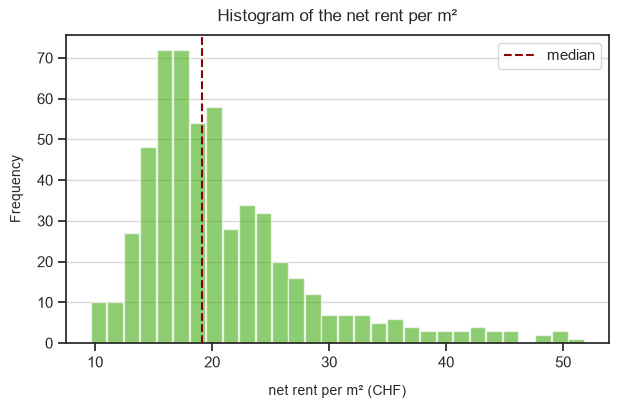

In [13]:
fig = plt.figure(figsize=(7, 4))
plt.hist(x=df['rent_net_per_m2'].dropna(), bins=30, color='#42AD12', alpha=0.6, rwidth=0.95)
plt.axvline(df['rent_net_per_m2'].median(), color='darkred', linestyle='dashed', label='median')
plt.xlabel('net rent per m² (CHF)', fontsize=10, labelpad=10)
plt.ylabel('Frequency', fontsize=10, labelpad=10)
plt.title('Histogram of the net rent per m²', fontsize=12, pad=10)
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()

### Bar chart: number of apartments by renovation group

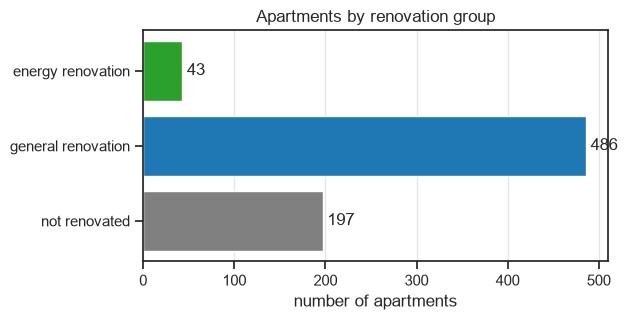

In [14]:
counts = df['renovation_group'].value_counts().reindex(groups)
fig = plt.figure(figsize=(6, 3))
plt.barh(counts.index, counts.values, color=[colors[g] for g in groups])
for i, v in enumerate(counts.values):
    plt.text(v + 5, i, str(v), va='center')
plt.xlabel('number of apartments')
plt.title('Apartments by renovation group')
plt.grid(axis='x', alpha=0.5)
plt.show()

## Multivariate graphical EDA

### Boxplots: net rent per m² by renovation group

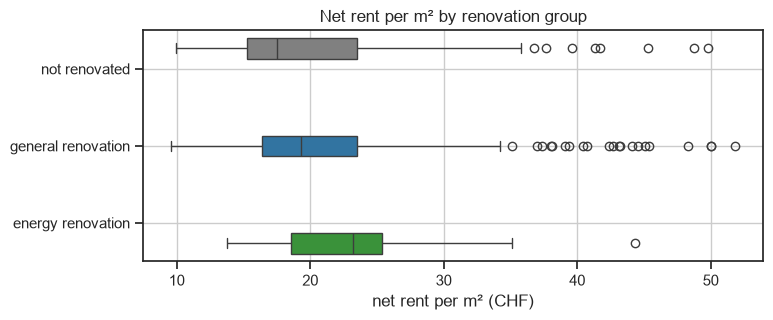

In [15]:
plt.figure(figsize=(8, 3))
sns.boxplot(x='rent_net_per_m2', y='renovation_group', hue='renovation_group', data=df,
            palette=colors, order=groups, legend=False, orient='h')
plt.xlabel('net rent per m² (CHF)')
plt.ylabel('')
plt.title('Net rent per m² by renovation group')
plt.grid()
plt.show()

### Boxplots: net rent per m² by renovation group and language region

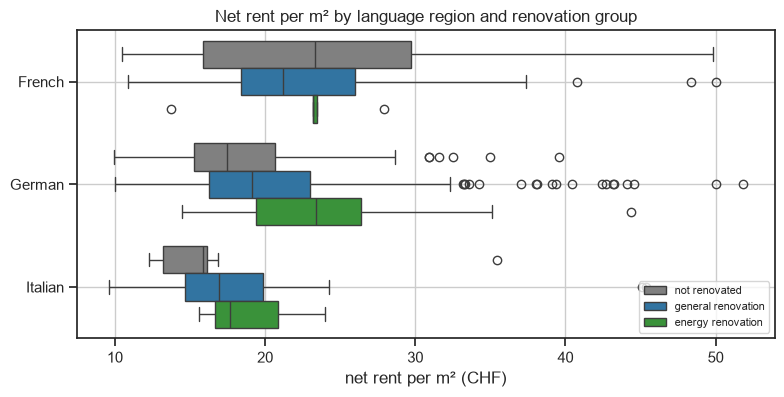

In [16]:
plt.figure(figsize=(9, 4))
sns.boxplot(x='rent_net_per_m2', y='language_region', hue='renovation_group', data=df,
            palette=colors, hue_order=groups, orient='h')
plt.xlabel('net rent per m² (CHF)')
plt.ylabel('')
plt.title('Net rent per m² by language region and renovation group')
plt.legend(loc='lower right', fontsize=8)
plt.grid()
plt.show()

### Bar chart: renovated parts and energy measures in the renovated groups

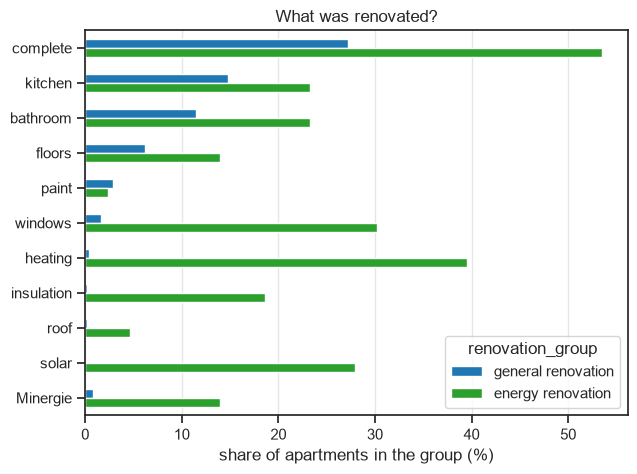

In [17]:
labels = {'reno_complete': 'complete', 'reno_kitchen': 'kitchen', 'reno_bathroom': 'bathroom',
          'reno_floors': 'floors', 'reno_paint': 'paint', 'energy_windows': 'windows',
          'energy_heating': 'heating', 'energy_insulation': 'insulation', 'energy_roof': 'roof',
          'energy_solar': 'solar', 'energy_minergie': 'Minergie'}
share = (df.groupby('renovation_group')[part_cols].mean() * 100).T.rename(index=labels)
share[['general renovation', 'energy renovation']].plot(kind='barh', figsize=(7, 5),
                                                        color=[colors['general renovation'], colors['energy renovation']])
plt.xlabel('share of apartments in the group (%)')
plt.title('What was renovated?')
plt.grid(axis='x', alpha=0.5)
plt.gca().invert_yaxis()
plt.show()

### Scatterplot: net rent per m² versus living area

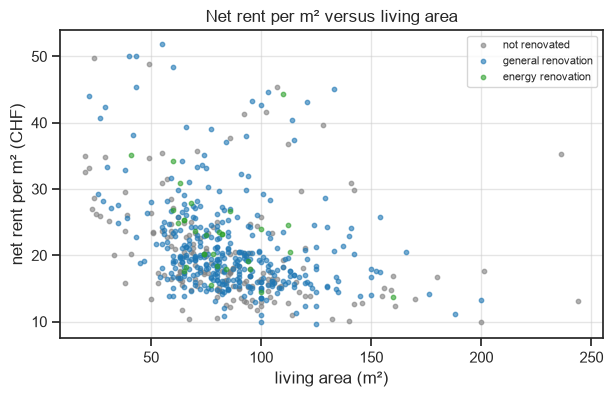

In [18]:
plt.figure(figsize=(7, 4))
for g in groups:
    sub = df[df['renovation_group'] == g]
    plt.scatter(sub['area'], sub['rent_net_per_m2'], s=10, alpha=0.6, color=colors[g], label=g)
plt.xlabel('living area (m²)')
plt.ylabel('net rent per m² (CHF)')
plt.title('Net rent per m² versus living area')
plt.legend(fontsize=8)
plt.grid(alpha=0.5)
plt.show()

### Scatterplot: net rent per m² versus population density (log scale) and taxable income

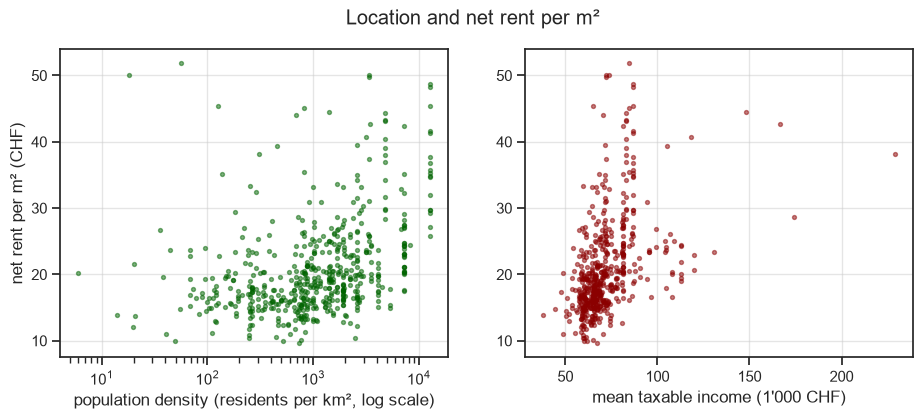

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(df['population_density'], df['rent_net_per_m2'], s=8, alpha=0.5, color='darkgreen')
axes[0].set_xscale('log')
axes[0].set_xlabel('population density (residents per km², log scale)')
axes[0].set_ylabel('net rent per m² (CHF)')
axes[1].scatter(df['mean_taxable_income'] / 1000, df['rent_net_per_m2'], s=8, alpha=0.5, color='darkred')
axes[1].set_xlabel("mean taxable income (1'000 CHF)")
for ax in axes:
    ax.grid(alpha=0.5)
plt.suptitle('Location and net rent per m²')
plt.show()

### Correlation heatmap

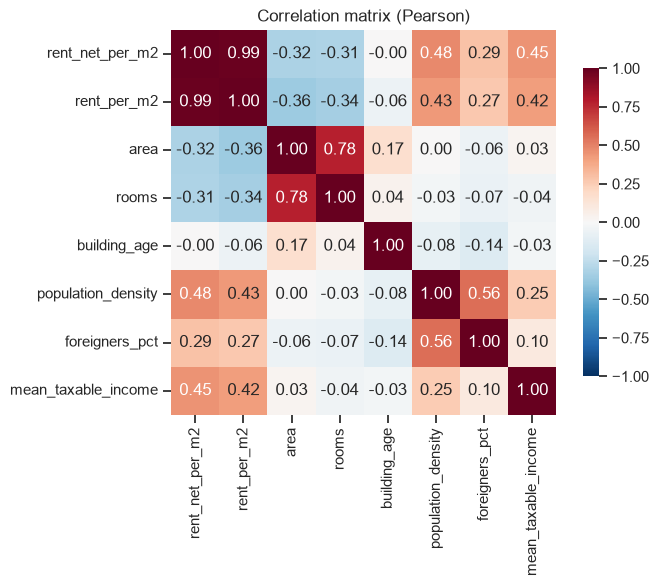

In [20]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, cbar_kws={'shrink': 0.8})
plt.title('Correlation matrix (Pearson)')
plt.show()

## Geographical data: map of the apartments

The coordinates are the centre of the postcode area (swisstopo), not the exact address. Apartments with the same postcode are moved by a small random amount (`jitter`), so that the points do not lie on top of each other. The map is also saved as `map_apartments.html` and can be opened in a web browser.

In [21]:
rng = np.random.default_rng(42)
df['lat_j'] = df['lat'] + rng.normal(0, 0.004, len(df))
df['lon_j'] = df['lon'] + rng.normal(0, 0.006, len(df))

m = folium.Map(location=[46.8, 8.2], zoom_start=8, tiles='OpenStreetMap')
for _, r in df.iterrows():
    folium.CircleMarker(location=[r['lat_j'], r['lon_j']],
                        radius=5 if r['renovation_group'] == 'energy renovation' else 3,
                        color=colors[r['renovation_group']],
                        fill=True, fill_opacity=0.8, weight=1,
                        popup=folium.Popup(f"{r['address']}<br>{r['rooms']} rooms, {r['area']} m²<br>"
                                           f"gross rent CHF {r['price']:.0f}<br>{r['renovation_group']}<br>"
                                           f"{r['renovated_parts']}", max_width=250)).add_to(m)

# Legend
legend = '''<div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999; background: white;
            padding: 8px; border: 1px solid grey; font-size: 13px;">
            <b>Renovation group</b><br>
            <span style="color: grey;">&#9679;</span> not renovated<br>
            <span style="color: #1f77b4;">&#9679;</span> general renovation<br>
            <span style="color: #2ca02c;">&#9679;</span> energy renovation</div>'''
m.get_root().html.add_child(folium.Element(legend))

m.save('map_apartments.html')
m

### Map by municipality: mean net rent per m² (static map with matplotlib)

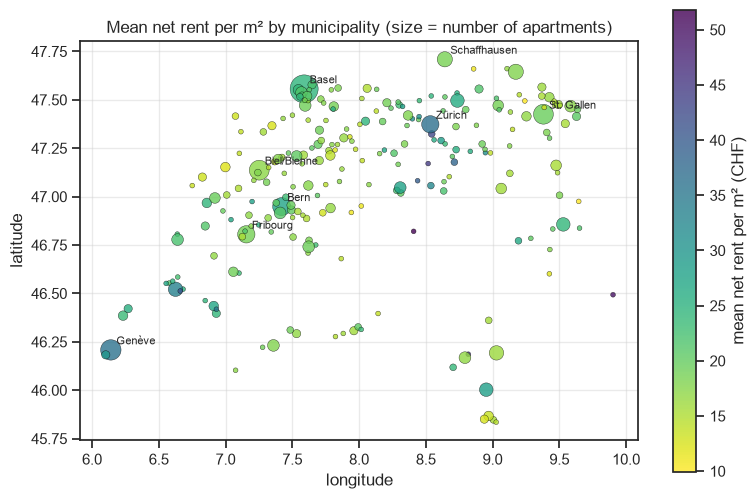

In [22]:
mun = (df.groupby(['bfs_number', 'bfs_name'])
         .agg(lat=('lat', 'mean'), lon=('lon', 'mean'), n=('apartment_id', 'count'),
              rent_net_m2=('rent_net_per_m2', 'mean'))
         .dropna()
         .reset_index())

fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(mun['lon'], mun['lat'], s=mun['n'] * 12, c=mun['rent_net_m2'], cmap='viridis_r',
                alpha=0.8, edgecolor='black', linewidth=0.3)
for _, r in mun.nlargest(8, 'n').iterrows():
    ax.annotate(r['bfs_name'], (r['lon'], r['lat']), fontsize=8, xytext=(4, 4), textcoords='offset points')
plt.colorbar(sc, label='mean net rent per m² (CHF)')
ax.set_xlabel('longitude')
ax.set_ylabel('latitude')
ax.set_title('Mean net rent per m² by municipality (size = number of apartments)')
ax.set_aspect(1.45)
ax.grid(alpha=0.4)
plt.show()

## Statistical tests

### One-way ANOVA: net rent per m² by renovation group

- H0: the mean net rent per m² is the same in all three renovation groups.
- H1: at least one group has a different mean.

ANOVA assumes normally distributed values and equal variances in the groups. Both are checked (Shapiro-Wilk, Levene). Welch's ANOVA (no equal variances needed) and the Kruskal-Wallis test (rank-based, no normal distribution needed) are shown as robustness checks, as in Week 12.

In [23]:
# Create subsets (groups)
g_none = df.loc[df['renovation_group'] == 'not renovated', 'rent_net_per_m2'].dropna()
g_gen = df.loc[df['renovation_group'] == 'general renovation', 'rent_net_per_m2'].dropna()
g_en = df.loc[df['renovation_group'] == 'energy renovation', 'rent_net_per_m2'].dropna()
print('n:', len(g_none), len(g_gen), len(g_en), '\n')

# Create ANOVA
fvalue, pvalue = stats.f_oneway(g_none, g_gen, g_en)
print(f'ANOVA F-value: {fvalue:.3f}, p-value: {pvalue:.4g}\n')

# Normality within groups (Shapiro-Wilk test, H0: values are normally distributed)
for name, group in [('not renovated', g_none), ('general renovation', g_gen), ('energy renovation', g_en)]:
    print(f'Shapiro-Wilk p-value ({name}): {stats.shapiro(group).pvalue:.4g}')

# Equal variances (Levene test, H0: variances are equal)
print(f'\nLevene test p-value: {stats.levene(g_none, g_gen, g_en).pvalue:.4g}')

# Welch's ANOVA (does not assume equal variances)
res_welch = anova_oneway([g_none, g_gen, g_en], use_var='unequal')
print(f"Welch's ANOVA F-value: {res_welch.statistic:.3f}, p-value: {res_welch.pvalue:.4g}")

# Rank-based Kruskal-Wallis test (does not assume normal distribution)
res_kw = stats.kruskal(g_none, g_gen, g_en)
print(f'Kruskal-Wallis H-value: {res_kw.statistic:.3f}, p-value: {res_kw.pvalue:.4g}')

n: 174 350 30 

ANOVA F-value: 2.519, p-value: 0.0815

Shapiro-Wilk p-value (not renovated): 2.765e-11
Shapiro-Wilk p-value (general renovation): 1.167e-18
Shapiro-Wilk p-value (energy renovation): 0.01577

Levene test p-value: 0.5298
Welch's ANOVA F-value: 2.835, p-value: 0.06462
Kruskal-Wallis H-value: 12.878, p-value: 0.001598


### Pairwise comparison: energy renovation versus not renovated (Welch t-test and Mann-Whitney U test)

A first answer to the main research question **without** control variables.

In [24]:
res_t = stats.ttest_ind(g_en, g_none, equal_var=False)
res_u = stats.mannwhitneyu(g_en, g_none, alternative='two-sided')
print(f'Mean difference (energy - not renovated): {g_en.mean() - g_none.mean():.2f} CHF per m²')
print(f'Welch t-test: t = {res_t.statistic:.3f}, p-value = {res_t.pvalue:.4g}')
print(f'Mann-Whitney U test: U = {res_u.statistic:.0f}, p-value = {res_u.pvalue:.4g}')

Mean difference (energy - not renovated): 3.13 CHF per m²
Welch t-test: t = 2.359, p-value = 0.02283
Mann-Whitney U test: U = 3543, p-value = 0.001792


### Chi-squared test: renovation group × language region

- H0: the renovation group is independent of the language region.
- H1: the share of the renovation groups differs between the language regions.

In [25]:
# Contingency table (numbers in the table are apartments)
tab = pd.crosstab(df['renovation_group'], df['language_region'])
print(tab, '\n')

# 1-alpha
prob = 0.95

# Chi-squared test
stat, p, dof, expected = chi2_contingency(tab)

# Critical value
critical = chi2.ppf(prob, dof)

# Print results of the Chi-square test
print('Expected frequencies:', '\n', expected.round(2), '\n')
print('Critical value:', critical.round(4))
print('Test statistic:', stat.round(4))
print('Degrees of freedom:', dof)
print(f'p-value: {p:.4f}\n')

# Check the assumption of the Chi-squared test (rule of thumb: at most 20% of the
# expected frequencies < 5 and no expected frequency < 1)
print(f'Expected frequencies < 5: {(expected < 5).sum()} of {expected.size} ({(expected < 5).mean() * 100:.0f} %)')
print(f'Expected frequencies < 1: {(expected < 1).sum()}')

language_region     French  German  Italian
renovation_group                           
not renovated           58     129       10
general renovation      83     377       26
energy renovation        6      34        3 

Expected frequencies: 
 [[ 39.89 146.53  10.58]
 [ 98.4  361.49  26.11]
 [  8.71  31.98   2.31]] 

Critical value: 9.4877
Test statistic: 14.6051
Degrees of freedom: 4
p-value: 0.0056

Expected frequencies < 5: 1 of 9 (11 %)
Expected frequencies < 1: 0


### Correlation analysis with p-values

Pearson (linear relationship) and Spearman (monotonic relationship, robust against extreme values) correlations between the net rent per m² and the numeric variables.

In [26]:
rows = []
for c in ['area', 'rooms', 'building_age', 'population_density', 'foreigners_pct', 'mean_taxable_income']:
    sub = df[['rent_net_per_m2', c]].dropna()
    r_p = stats.pearsonr(sub[c], sub['rent_net_per_m2'])
    r_s = stats.spearmanr(sub[c], sub['rent_net_per_m2'])
    rows.append({'variable': c, 'n': len(sub),
                 'pearson_r': r_p.statistic, 'pearson_p': r_p.pvalue,
                 'spearman_rho': r_s.statistic, 'spearman_p': r_s.pvalue})
pd.DataFrame(rows).round(4)

,variable,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,area,554,-0.3153,0.0000,-0.3985,0.0000
1,rooms,554,-0.3095,0.0000,-0.3653,0.0000
2,building_age,543,-0.0010,0.9819,0.0067,0.8762
3,population_density,554,0.4804,0.0000,0.4381,0.0000
4,foreigners_pct,554,0.2850,0.0000,0.2527,0.0000
5,mean_taxable_income,550,0.4463,0.0000,0.5526,0.0000


## Summary of the EDA

The printed results above are summarised in the presentation. Main points to look at:

- distribution of the target variable (skewness, extreme values)
- differences between the renovation groups **without** controls (boxplots, ANOVA, t-test)
- differences in location between the groups (cross table, Chi-squared test): if energy-renovated apartments are more often in expensive regions, the simple comparison is biased, which is why the regression controls for location
- which control variables are correlated with the net rent per m² (correlation table)

### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [27]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
NT
Windows | 10
Datetime: 2026-11-26 15:45:51
Python Version: 3.11.8
-----------------------------------
